Few-Shot Medical Image Segmentation

---## 0 · Setup: install, download, extract

In [ ]:
import os, sys, shutil, zipfile, subprocess, random, time
from pathlib import Path
from statistics import mean

# ─── Working directory ───
os.makedirs("/content", exist_ok=True)
os.chdir("/content")

# ─── Install dependencies (the notebook contains all project code) ───
# The unavailable group repository was used only for requirements.txt.
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "torch", "torchvision", "numpy", "pillow", "matplotlib"], check=True)

# ─── Download the original dataset from your GitHub Release ───
from urllib.request import urlretrieve

DATA_URL = (
    "https://github.com/TheSkyEr4998/"
    "Few-shot-Learning-for-Medical-Image-Segmentation/"
    "releases/download/data-v1/ems741_cw_data.zip"
)
ZIP_PATH = "/content/ems741_cw_data.zip"

if not os.path.exists(ZIP_PATH):
    print("Downloading dataset from your GitHub Release...")
    urlretrieve(DATA_URL, ZIP_PATH)
else:
    print("Zip already exists.")

# ─── Auto-detect dataset root ───
def find_dataset_root(search_root="/content", max_depth=4):
    search_root = Path(search_root)
    candidates = []
    for root, dirs, files in os.walk(search_root):
        rp = Path(root)
        try:
            depth = len(rp.relative_to(search_root).parts)
        except:
            depth = 999
        if depth > max_depth:
            dirs[:] = []
            continue
        if {"train", "val", "test"}.issubset(set(dirs)):
            candidates.append(rp)
    if not candidates:
        return None
    for c in candidates:
        if c.name == "ems741_cw_data":
            return c
    return sorted(candidates, key=lambda x: len(x.parts))[0]

existing = find_dataset_root()
if existing is None:
    print("Extracting...")
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("/content")

DATA_ROOT = find_dataset_root()
if DATA_ROOT is None:
    raise FileNotFoundError("Cannot find train/val/test under /content")

print(f"\nDATA_ROOT: {DATA_ROOT}")
for s in ["train", "val", "test"]:
    sp = DATA_ROOT / s
    if sp.exists():
        tasks = sorted(d.name for d in sp.iterdir() if d.is_dir() and not d.name.startswith("."))
        print(f"  {s.upper():5s} -> {tasks}")

# ─── PyTorch + GPU ───
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import copy
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nDevice: {DEVICE}", end="")
if DEVICE.type == "cuda":
    print(f" ({torch.cuda.get_device_name(0)})")
else:
    print(" *** WARNING: No GPU detected! ***")

print("\nSetup complete.")

Zip already exists.

DATA_ROOT: /content
  TRAIN -> ['task_2', 'task_3', 'task_5', 'task_7']
  VAL   -> ['task_4', 'task_6']
  TEST  -> ['task_1', 'task_8']

Device: cuda (Tesla T4)

Setup complete.


In [ ]:
# U Net #

class DoubleConv(nn.Module):
    def __init__(self, inc, outc):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(inc, outc, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(outc, outc, 3, padding=1), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class Down(nn.Module):
    def __init__(self, inc, outc):
        super().__init__()
        self.block = nn.Sequential(nn.MaxPool2d(2, 2), DoubleConv(inc, outc))
    def forward(self, x): return self.block(x)

class Up(nn.Module):
    def __init__(self, inc, skipc, outc):
        super().__init__()
        self.up = nn.ConvTranspose2d(inc, inc // 2, 2, stride=2)
        self.conv = DoubleConv(inc // 2 + skipc, outc)
    def forward(self, x, skip):
        x = self.up(x)
        dy, dx = skip.size(2) - x.size(2), skip.size(3) - x.size(3)
        x = F.pad(x, [dx//2, dx-dx//2, dy//2, dy-dy//2])
        return self.conv(torch.cat([skip, x], 1))

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        c1,c2,c3,c4,c5 = base, base*2, base*4, base*8, base*16
        self.inc = DoubleConv(in_ch, c1)
        self.d1, self.d2, self.d3, self.d4 = Down(c1,c2), Down(c2,c3), Down(c3,c4), Down(c4,c5)
        self.u1, self.u2, self.u3, self.u4 = Up(c5,c4,c4), Up(c4,c3,c3), Up(c3,c2,c2), Up(c2,c1,c1)
        self.outc = nn.Conv2d(c1, out_ch, 1)
    def forward(self, x):
        x1=self.inc(x); x2=self.d1(x1); x3=self.d2(x2); x4=self.d3(x3); x5=self.d4(x4)
        x=self.u1(x5,x4); x=self.u2(x,x3); x=self.u3(x,x2); x=self.u4(x,x1)
        return self.outc(x)

# Sanity check
_m = UNet().to(DEVICE); _x = torch.randn(2,1,192,192).to(DEVICE)
print(f"U-Net params: {sum(p.numel() for p in _m.parameters()):,}")
print(f"Input: {_x.shape} -> Output: {_m(_x).shape}")
del _m, _x; torch.cuda.empty_cache()

U-Net params: 7,759,521
Input: torch.Size([2, 1, 192, 192]) -> Output: torch.Size([2, 1, 192, 192])


In [ ]:
#Loss + Metric #

def soft_dice_loss(logits, targets, eps=1e-6):
    p = torch.sigmoid(logits).view(logits.size(0), -1)
    t = targets.view(targets.size(0), -1)
    inter = (p * t).sum(1)
    union = p.sum(1) + t.sum(1)
    return 1.0 - ((2*inter + eps) / (union + eps)).mean()

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_w=0.5, dice_w=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_w, self.dice_w = bce_w, dice_w
    def forward(self, logits, targets):
        return self.bce_w * self.bce(logits, targets) + self.dice_w * soft_dice_loss(logits, targets)

@torch.no_grad()
def dice_score(logits, targets, thr=0.5, eps=1e-6):
    preds = (torch.sigmoid(logits) > thr).float().view(logits.size(0), -1)
    tgts = targets.view(targets.size(0), -1)
    inter = (preds * tgts).sum(1)
    union = preds.sum(1) + tgts.sum(1)
    valid = union > 0
    if valid.sum() == 0: return 0.0
    return ((2*inter[valid]+eps) / (union[valid]+eps)).mean().item()

@torch.no_grad()
def iou_score(logits, targets, thr=0.5, eps=1e-6):
    preds = (torch.sigmoid(logits) > thr).float().view(logits.size(0), -1)
    tgts = targets.view(targets.size(0), -1)
    inter = (preds * tgts).sum(1)
    union = preds.sum(1) + tgts.sum(1) - inter
    valid = union > 0
    if valid.sum() == 0: return 0.0
    return ((inter[valid]+eps) / (union[valid]+eps)).mean().item()

print("Loss & metrics ready (empty-mask fix applied).")

Loss & metrics ready (empty-mask fix applied).


In [ ]:
# Data Pipeline #
IMAGE_SIZE = (192, 192)

img_tf = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor()])
mask_tf = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.NEAREST),
    transforms.ToTensor()])

def csl(folder):
    return sorted(f for f in os.listdir(folder) if not f.startswith("."))

def get_task_names(split):
    sp = DATA_ROOT / split
    return [n for n in csl(sp) if (sp / n).is_dir()]

def load_task(split, task):
    tp = DATA_ROOT / split / task
    files = csl(tp / "images")
    imgs, msks = [], []
    for f in files:
        imgs.append(img_tf(Image.open(tp/"images"/f).convert("L")))
        m = mask_tf(Image.open(tp/"masks"/f).convert("L"))
        msks.append((m > 0.5).float())
    return imgs, msks, files

def sample_episode(split, task, k, query_size=None, seed=None):
    rng = random.Random(seed) if seed else random
    imgs, msks, fns = load_task(split, task)
    n = len(imgs)
    idx = list(range(n)); rng.shuffle(idx)
    s_idx = idx[:k]; rem = idx[k:]
    q_idx = rem if query_size is None else rng.sample(rem, min(query_size, len(rem)))
    return {
        "task": task,
        "support_images": torch.stack([imgs[i] for i in s_idx]),
        "support_masks":  torch.stack([msks[i] for i in s_idx]),
        "query_images":   torch.stack([imgs[i] for i in q_idx]),
        "query_masks":    torch.stack([msks[i] for i in q_idx]),
    }

print("Data pipeline ready.")

Data pipeline ready.


In [ ]:
# Data verify + Visualize Samples #
# Verify
for split in ["train", "val", "test"]:
    tasks = get_task_names(split)
    print(f"{split.upper():5s}: {tasks}")
    for t in tasks:
        tp = DATA_ROOT / split / t
        n_img = len(csl(tp / "images"))
        n_msk = len(csl(tp / "masks"))
        print(f"  {t}: {n_img} images, {n_msk} masks {'OK' if n_img==n_msk else 'MISMATCH!'}")

print("\nDataset OK.")

TRAIN: ['task_2', 'task_3', 'task_5', 'task_7']
  task_2: 1011 images, 1011 masks OK
  task_3: 1336 images, 1336 masks OK
  task_5: 709 images, 709 masks OK
  task_7: 520 images, 520 masks OK
VAL  : ['task_4', 'task_6']
  task_4: 805 images, 805 masks OK
  task_6: 1584 images, 1584 masks OK
TEST : ['task_1', 'task_8']
  task_1: 775 images, 775 masks OK
  task_8: 648 images, 648 masks OK

Dataset OK.


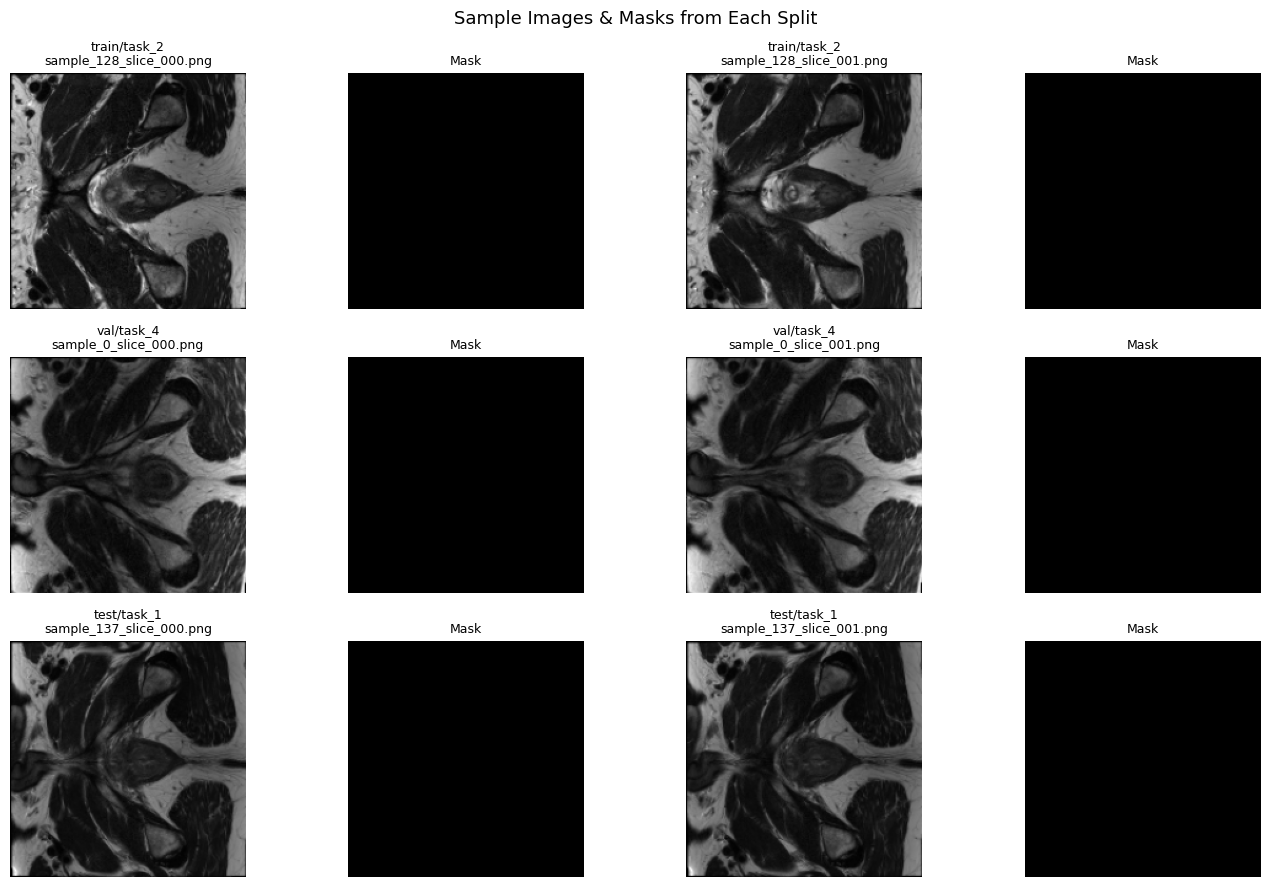

Saved: sample_data.png


In [ ]:
# Visualize samples from each split
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for row, split in enumerate(["train", "val", "test"]):
    task = get_task_names(split)[0]
    imgs, msks, fns = load_task(split, task)
    for col in range(2):
        axes[row, col*2].imshow(imgs[col].squeeze(0).numpy(), cmap="gray")
        axes[row, col*2].set_title(f"{split}/{task}\n{fns[col]}", fontsize=9)
        axes[row, col*2].axis("off")
        axes[row, col*2+1].imshow(msks[col].squeeze(0).numpy(), cmap="gray")
        axes[row, col*2+1].set_title("Mask", fontsize=9)
        axes[row, col*2+1].axis("off")
plt.suptitle("Sample Images & Masks from Each Split", fontsize=13)
plt.tight_layout()
plt.savefig("sample_data.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: sample_data.png")

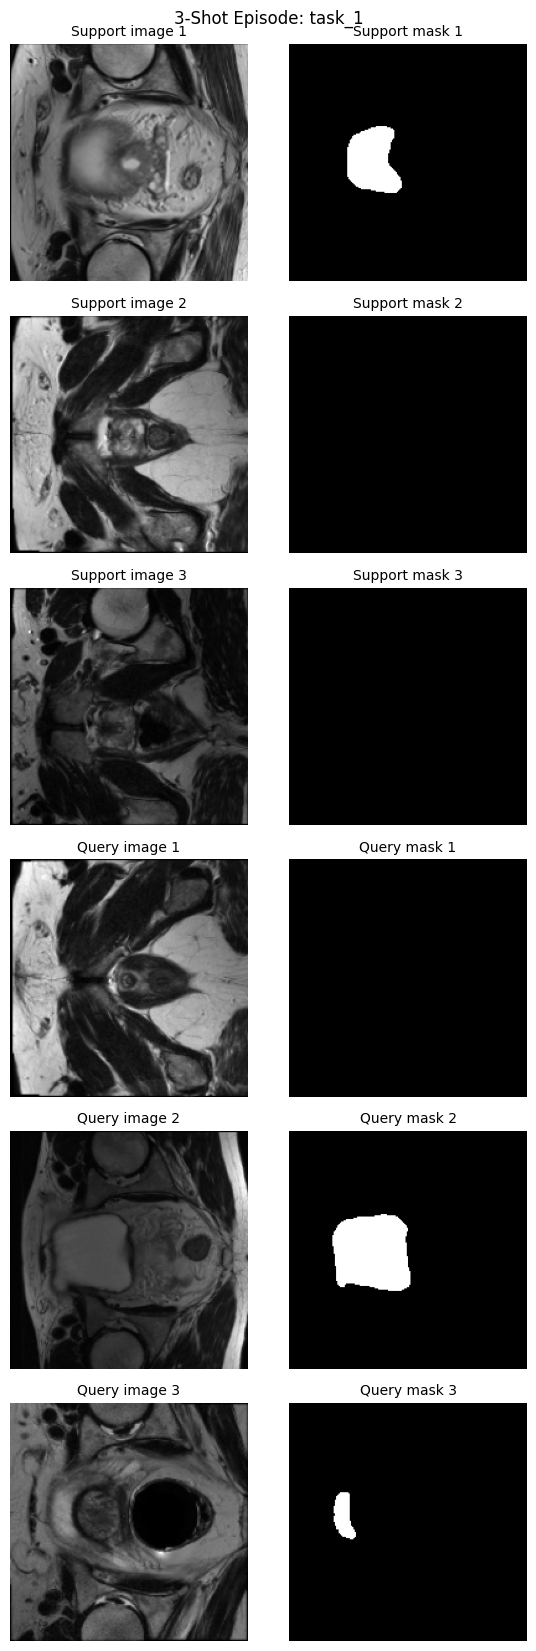

In [ ]:
## 5 · Few-shot episode visualization
# Show a 3-shot episode

task = get_task_names("test")[0]
ep = sample_episode("test", task, k=3, query_size=3, seed=42)

total = ep["support_images"].shape[0] + ep["query_images"].shape[0]
fig, axes = plt.subplots(total, 2, figsize=(6, 2.8*total))

for i in range(ep["support_images"].shape[0]):
    axes[i,0].imshow(ep["support_images"][i].squeeze(0).numpy(), cmap="gray")
    axes[i,0].set_title(f"Support image {i+1}", fontsize=10); axes[i,0].axis("off")
    axes[i,1].imshow(ep["support_masks"][i].squeeze(0).numpy(), cmap="gray")
    axes[i,1].set_title(f"Support mask {i+1}", fontsize=10); axes[i,1].axis("off")

offset = ep["support_images"].shape[0]
for i in range(ep["query_images"].shape[0]):
    axes[offset+i,0].imshow(ep["query_images"][i].squeeze(0).numpy(), cmap="gray")
    axes[offset+i,0].set_title(f"Query image {i+1}", fontsize=10); axes[offset+i,0].axis("off")
    axes[offset+i,1].imshow(ep["query_masks"][i].squeeze(0).numpy(), cmap="gray")
    axes[offset+i,1].set_title(f"Query mask {i+1}", fontsize=10); axes[offset+i,1].axis("off")

plt.suptitle(f"3-Shot Episode: {task}", fontsize=12)
plt.tight_layout()
plt.savefig("episode_example.png", dpi=200, bbox_inches="tight")
plt.show()
#print("Saved: episode_example.png")

In [ ]:
# Reptile Meta training
CHECKPOINT_PATH = Path("/content/best_reptile_unet.pt")

def set_seed(seed):
    random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def linear_meta_step(it, total, initial, final):
    return initial + ((it-1) / max(total-1, 1)) * (final - initial)

def adapt_task(meta_model, s_img, s_msk, inner_iters, inner_lr):
    fast = copy.deepcopy(meta_model).to(DEVICE)
    fast.train()
    s_img, s_msk = s_img.to(DEVICE), s_msk.to(DEVICE)
    crit = BCEDiceLoss()
    opt = optim.Adam(fast.parameters(), lr=inner_lr)
    for _ in range(inner_iters):
        loss = crit(fast(s_img), s_msk)
        opt.zero_grad(); loss.backward(); opt.step()
    return fast

@torch.no_grad()
def get_delta(meta, adapted):
    ms, ad = meta.state_dict(), adapted.state_dict()
    return {k: ad[k] - ms[k] for k in ms}

@torch.no_grad()
def avg_deltas(deltas):
    return {k: torch.stack([d[k] for d in deltas]).mean(0) for k in deltas[0]}

@torch.no_grad()
def apply_update(model, delta, step):
    st = model.state_dict()
    for k in st: st[k] = st[k] + step * delta[k]
    model.load_state_dict(st)

@torch.no_grad()
def eval_query(model, q_img, q_msk):
    model.eval()
    q_img, q_msk = q_img.to(DEVICE), q_msk.to(DEVICE)
    logits = model(q_img)
    return {"loss": BCEDiceLoss()(logits, q_msk).item(),
            "dice": dice_score(logits, q_msk), "iou": iou_score(logits, q_msk)}

def eval_split(meta_model, split, k_shot=3, query_size=10,
               inner_iters=20, inner_lr=3e-3, repeats=2, seed=42):
    tasks = get_task_names(split)
    L, D, I = [], [], []
    for ti, tn in enumerate(tasks):
        for r in range(repeats):
            ep = sample_episode(split, tn, k=k_shot, query_size=query_size, seed=seed+1000*ti+r)
            ad = adapt_task(meta_model, ep["support_images"], ep["support_masks"], inner_iters, inner_lr)
            m = eval_query(ad, ep["query_images"], ep["query_masks"])
            L.append(m["loss"]); D.append(m["dice"]); I.append(m["iou"])
    return {"loss": mean(L), "dice": mean(D), "iou": mean(I)}

print("Reptile helpers ready.")

Reptile helpers ready.


In [ ]:
# DIAGNOSTIC: does inner loop adapt?
print("Running diagnostic...\n")
dt = get_task_names("train")[0]
ep = sample_episode("train", dt, k=3, query_size=5, seed=42)

m0 = UNet().to(DEVICE); crit = BCEDiceLoss()
si, sm = ep["support_images"].to(DEVICE), ep["support_masks"].to(DEVICE)

m0.eval()
with torch.no_grad():
    lg = m0(si)
    print(f"Before: Loss={crit(lg,sm).item():.4f}  Dice={dice_score(lg,sm):.4f}  FG={(torch.sigmoid(lg)>0.5).sum().item():.0f}")

ad = adapt_task(m0, si, sm, inner_iters=20, inner_lr=3e-3)
ad.eval()
with torch.no_grad():
    lg = ad(si)
    print(f"After:  Loss={crit(lg,sm).item():.4f}  Dice={dice_score(lg,sm):.4f}  FG={(torch.sigmoid(lg)>0.5).sum().item():.0f}")

del m0, ad, si, sm; torch.cuda.empty_cache()
print("\nDiagnostic complete.")

Running diagnostic...

Before: Loss=0.7702  Dice=0.0000  FG=0
After:  Loss=0.5651  Dice=0.0000  FG=0

Diagnostic complete.


In [ ]:
def meta_train_reptile(
    num_iterations=800,
    meta_batch_size=4,
    train_k_shot=3,
    query_size=10,
    inner_iters=20,
    inner_lr=3e-3,
    meta_step_initial=0.15,
    meta_step_final=0.01,
    val_every=50,
    repeats_per_val_task=2,
    seed=42,
    patience=120,
):
    """Fine-tuned Reptile: deeper inner loop, gentler meta step."""
    set_seed(seed)
    meta_model = UNet().to(DEVICE)
    train_tasks = get_task_names("train")
    n_params = sum(p.numel() for p in meta_model.parameters())

    print(f"\n{'='*60}")
    print(f"REPTILE META-TRAINING (FINE-TUNED)")
    print(f"{'='*60}")
    print(f"Device:     {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU'})")
    print(f"Params:     {n_params:,}")
    print(f"Tasks:      {train_tasks}")
    print(f"Config:     {num_iterations} iters, batch={meta_batch_size}")
    print(f"Inner:      {inner_iters} steps Adam @ lr={inner_lr}")
    print(f"Meta step:  {meta_step_initial} -> {meta_step_final}")
    print(f"Patience:   {patience}")
    print(f"{'='*60}\n")

    best_dice = -1.0
    no_improve = 0
    t0 = time.time()
    history = {"iter":[], "loss":[], "dice":[], "iou":[], "step":[]}

    for it in range(1, num_iterations + 1):
        ms = linear_meta_step(it, num_iterations, meta_step_initial, meta_step_final)
        deltas = []
        for bi in range(meta_batch_size):
            tn = random.choice(train_tasks)
            ep = sample_episode("train", tn, k=train_k_shot, query_size=query_size, seed=seed+it*100+bi)
            ad = adapt_task(meta_model, ep["support_images"], ep["support_masks"], inner_iters, inner_lr)
            deltas.append(get_delta(meta_model, ad))
        apply_update(meta_model, avg_deltas(deltas), ms)

        if it % val_every == 0 or it == 1:
            vm = eval_split(meta_model, "val", k_shot=train_k_shot, query_size=query_size,
                             inner_iters=inner_iters, inner_lr=inner_lr, repeats=repeats_per_val_task, seed=seed)
            history["iter"].append(it); history["loss"].append(vm["loss"])
            history["dice"].append(vm["dice"]); history["iou"].append(vm["iou"]); history["step"].append(ms)

            elapsed = time.time() - t0
            eta = (elapsed / it) * (num_iterations - it)
            tag = ""
            if vm["dice"] > best_dice:
                best_dice = vm["dice"]
                torch.save(meta_model.state_dict(), CHECKPOINT_PATH)
                tag = f"  ** BEST **"
                no_improve = 0
            else:
                no_improve += 1

            print(f"Iter {it:04d}/{num_iterations} | Step {ms:.4f} | "
                  f"Loss: {vm['loss']:.4f} | Dice: {vm['dice']:.4f} | IoU: {vm['iou']:.4f} | "
                  f"{elapsed/60:.1f}m (ETA {eta/60:.1f}m){tag}")

            if no_improve >= patience:
                print(f"\nEarly stopping ({patience} validations without improvement)")
                break

    print(f"\nDone in {(time.time()-t0)/60:.1f} min | Best Val Dice: {best_dice:.4f}")
    return meta_model, history

In [ ]:
#Run Meta Training #
meta_model, history = meta_train_reptile()


REPTILE META-TRAINING (FINE-TUNED)
Device:     cuda (Tesla T4)
Params:     7,759,521
Tasks:      ['task_2', 'task_3', 'task_5', 'task_7']
Config:     800 iters, batch=4
Inner:      20 steps Adam @ lr=0.003
Meta step:  0.15 -> 0.01
Patience:   120

Iter 0001/800 | Step 0.1500 | Loss: 0.5390 | Dice: 0.0000 | IoU: 0.0000 | 0.4m (ETA 295.0m)  ** BEST **
Iter 0050/800 | Step 0.1414 | Loss: 0.5496 | Dice: 0.0005 | IoU: 0.0002 | 8.2m (ETA 123.0m)  ** BEST **
Iter 0100/800 | Step 0.1327 | Loss: 0.4777 | Dice: 0.0037 | IoU: 0.0020 | 16.0m (ETA 112.1m)  ** BEST **
Iter 0150/800 | Step 0.1239 | Loss: 2.3342 | Dice: 0.4119 | IoU: 0.3159 | 23.6m (ETA 102.2m)  ** BEST **
Iter 0200/800 | Step 0.1151 | Loss: 0.6531 | Dice: 0.4195 | IoU: 0.3182 | 31.2m (ETA 93.6m)  ** BEST **
Iter 0250/800 | Step 0.1064 | Loss: 1.7140 | Dice: 0.4020 | IoU: 0.3069 | 38.6m (ETA 84.9m)
Iter 0300/800 | Step 0.0976 | Loss: 2.1851 | Dice: 0.3536 | IoU: 0.2603 | 46.2m (ETA 77.0m)
Iter 0350/800 | Step 0.0888 | Loss: 398.5382 

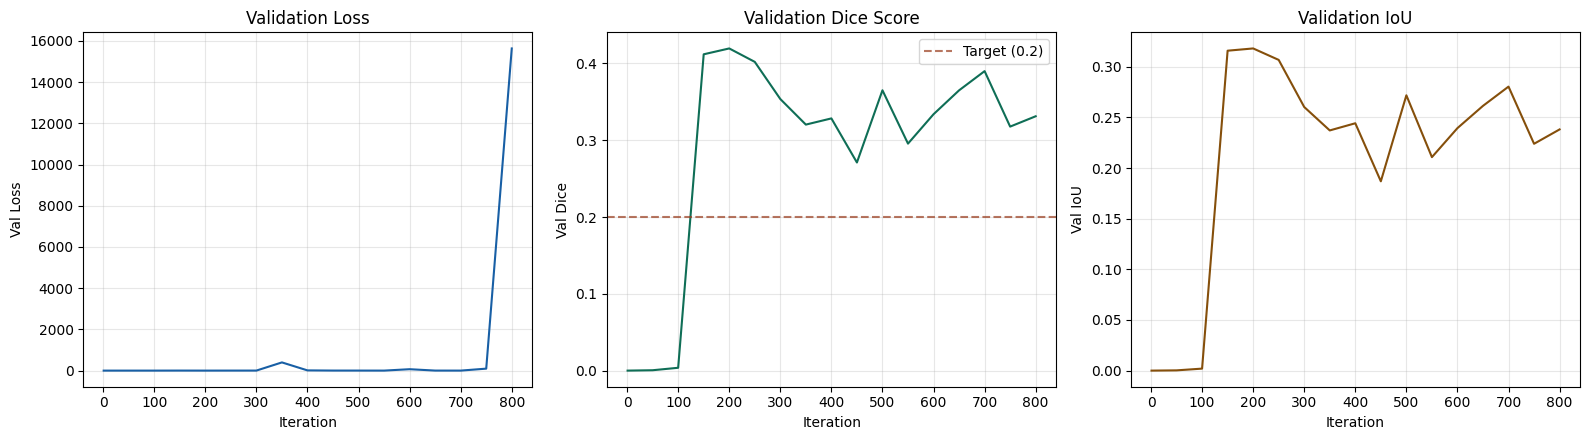

Saved: training_curves.png


In [ ]:
#Training cureve #
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(history["iter"], history["loss"], color="#185FA5", linewidth=1.5)
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Val Loss"); axes[0].set_title("Validation Loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["iter"], history["dice"], color="#0F6E56", linewidth=1.5)
axes[1].axhline(y=0.2, color="#993C1D", linestyle="--", alpha=0.7, label="Target (0.2)")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Val Dice"); axes[1].set_title("Validation Dice Score")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(history["iter"], history["iou"], color="#854F0B", linewidth=1.5)
axes[2].set_xlabel("Iteration"); axes[2].set_ylabel("Val IoU"); axes[2].set_title("Validation IoU")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: training_curves.png")

In [ ]:
#Final Testing 1 3 5 - shot
def test_model(k_values=(1, 3, 5, 10), inner_iters=20, inner_lr=3e-3,
               query_size=10, repeats=5, seed=42):
    model = UNet().to(DEVICE)
    model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))

    print(f"\n{'='*60}")
    print(f"FINAL TEST RESULTS")
    print(f"Inner loop: {inner_iters} steps Adam @ lr={inner_lr}")
    print(f"{'='*60}")

    results = {}
    for k in k_values:
        m = eval_split(model, "test", k_shot=k, query_size=query_size,
                        inner_iters=inner_iters, inner_lr=inner_lr, repeats=repeats, seed=seed)
        status = "PASS" if m["dice"] > 0.2 else "BELOW 0.2"
        print(f"  {k:2d}-shot | Loss: {m['loss']:.4f} | Dice: {m['dice']:.4f} | IoU: {m['iou']:.4f} | {status}")
        results[k] = m
    return results

test_results = test_model()


FINAL TEST RESULTS
Inner loop: 20 steps Adam @ lr=0.003
   1-shot | Loss: 6.1174 | Dice: 0.2120 | IoU: 0.1523 | PASS
   3-shot | Loss: 100.8687 | Dice: 0.2199 | IoU: 0.1604 | PASS
   5-shot | Loss: 4.2084 | Dice: 0.2530 | IoU: 0.1872 | PASS
  10-shot | Loss: 1.0525 | Dice: 0.2992 | IoU: 0.2165 | PASS


In [ ]:
#Result Summary table
print(f"\n{'='*62}")
print(f"  {'K-Shot':<10} {'Loss':<12} {'Dice Score':<14} {'IoU Score':<14} {'Status'}")
print(f"  {'-'*58}")
for k in sorted(test_results):
    m = test_results[k]
    st = "PASS" if m["dice"] > 0.2 else "BELOW TARGET"
    print(f"  {k:<10} {m['loss']:<12.4f} {m['dice']:<14.4f} {m['iou']:<14.4f} {st}")
print(f"  {'-'*58}")
best_k = max(test_results, key=lambda k: test_results[k]["dice"])
print(f"\n  Best: {best_k}-shot (Dice={test_results[best_k]['dice']:.4f})")


  K-Shot     Loss         Dice Score     IoU Score      Status
  ----------------------------------------------------------
  1          6.1174       0.2120         0.1523         PASS
  3          100.8687     0.2199         0.1604         PASS
  5          4.2084       0.2530         0.1872         PASS
  10         1.0525       0.2992         0.2165         PASS
  ----------------------------------------------------------

  Best: 10-shot (Dice=0.2992)


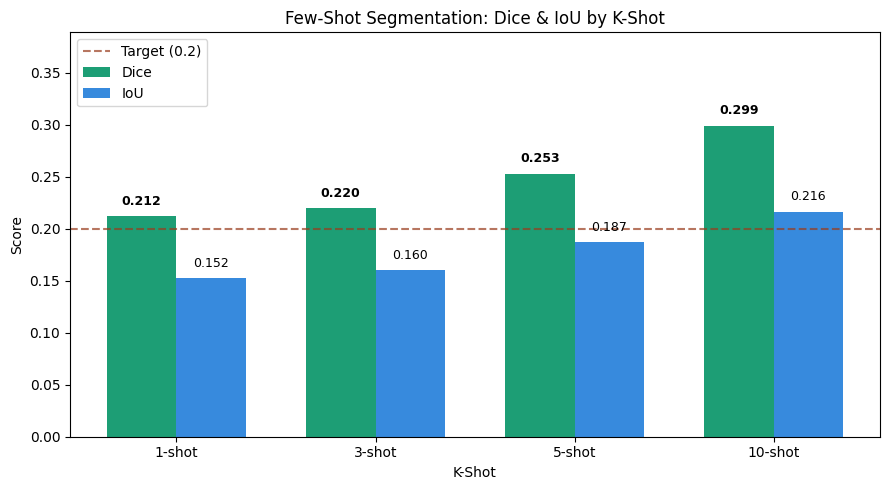

Saved: kshot_bar_chart.png


In [ ]:
#K shot comparison bar chart
ks = sorted(test_results.keys())
d_vals = [test_results[k]["dice"] for k in ks]
i_vals = [test_results[k]["iou"] for k in ks]

fig, ax = plt.subplots(figsize=(9, 5))
x = range(len(ks)); w = 0.35
b1 = ax.bar([i-w/2 for i in x], d_vals, w, label="Dice", color="#1D9E75")
b2 = ax.bar([i+w/2 for i in x], i_vals, w, label="IoU", color="#378ADD")
ax.axhline(y=0.2, color="#993C1D", linestyle="--", alpha=0.7, label="Target (0.2)")

for b in b1:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.008, f"{b.get_height():.3f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
for b in b2:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.008, f"{b.get_height():.3f}",
            ha="center", va="bottom", fontsize=9)

ax.set_xticks(list(x)); ax.set_xticklabels([f"{k}-shot" for k in ks])
ax.set_xlabel("K-Shot"); ax.set_ylabel("Score")
ax.set_title("Few-Shot Segmentation: Dice & IoU by K-Shot")
ax.legend(); ax.set_ylim(0, max(max(d_vals), max(i_vals)) * 1.3)
plt.tight_layout()
plt.savefig("kshot_bar_chart.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: kshot_bar_chart.png")

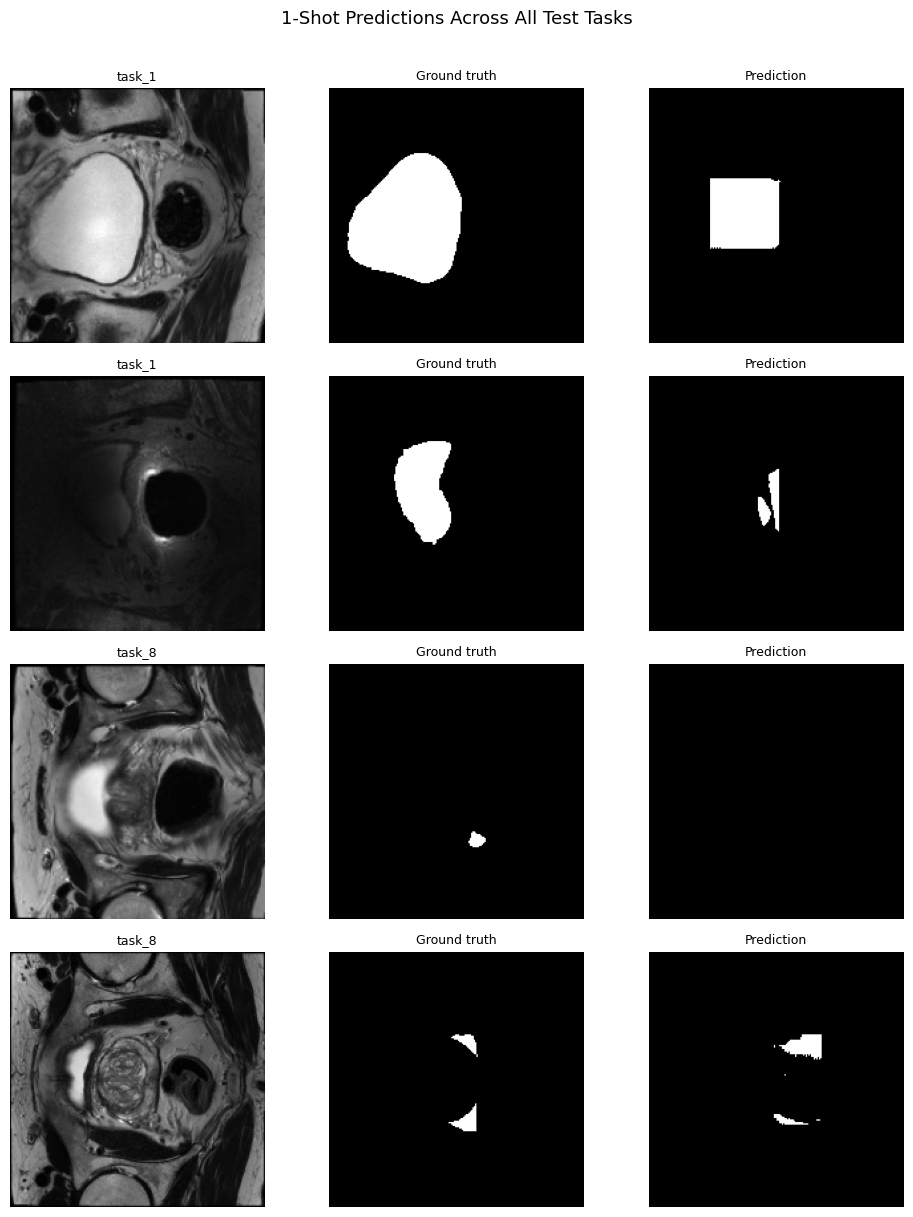

Saved: predictions_1shot.png


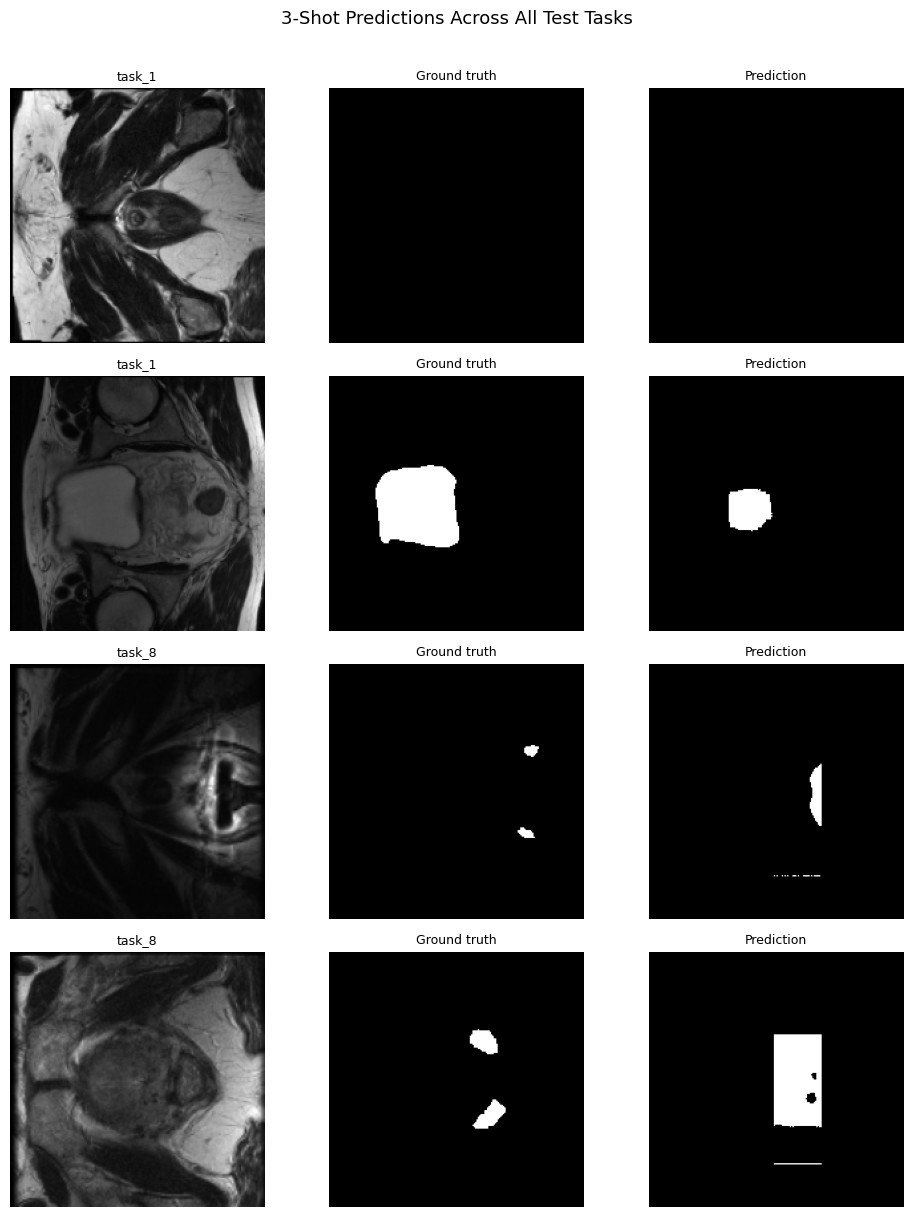

Saved: predictions_3shot.png


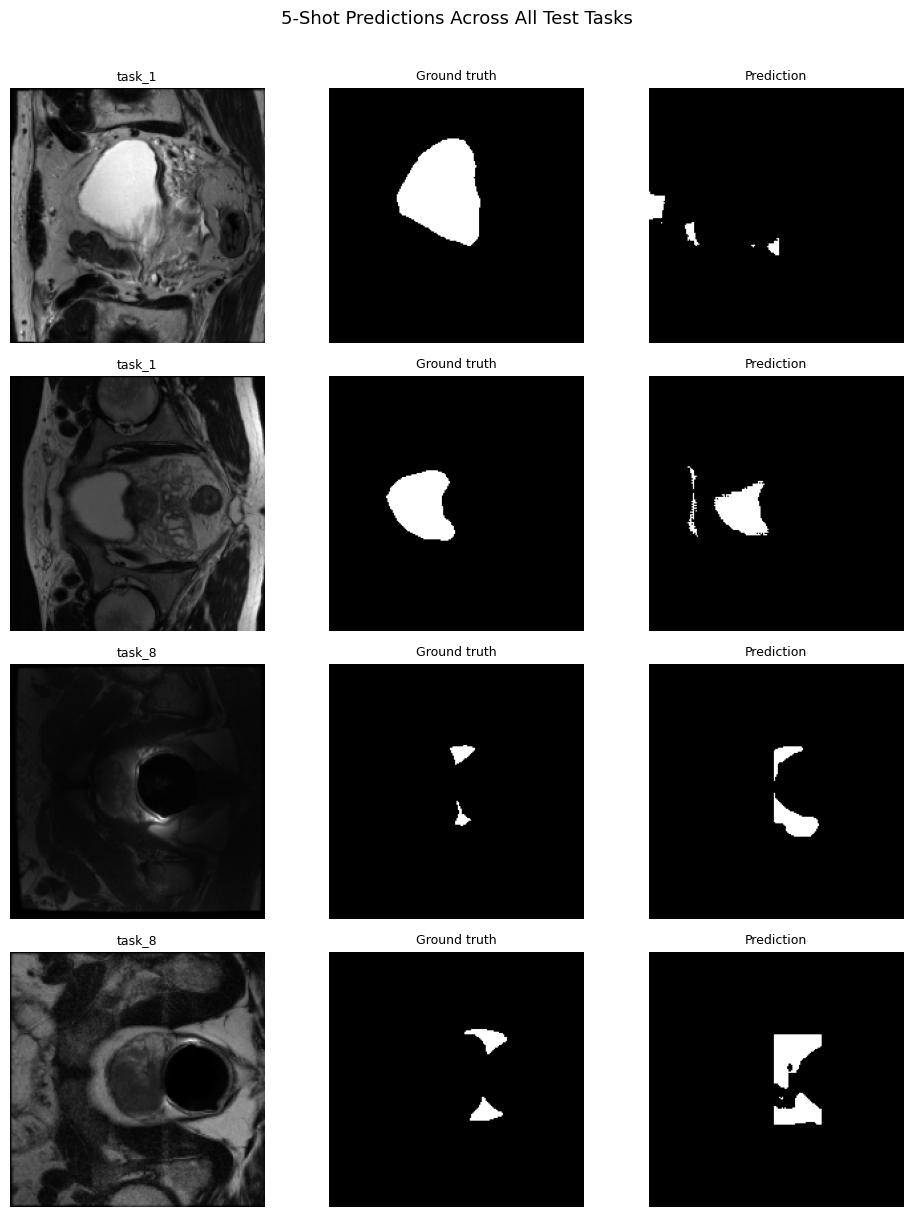

Saved: predictions_5shot.png


In [ ]:
## 11 · Prediction visualizations (all test tasks)
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))

for k in [1, 3, 5]:
    test_tasks = get_task_names("test")
    n_q = 2  # queries per task

    fig, axes = plt.subplots(len(test_tasks) * n_q, 3, figsize=(10, 3 * len(test_tasks) * n_q))
    if len(test_tasks) * n_q == 1:
        axes = axes.reshape(1, -1)

    row = 0
    for task in test_tasks:
        ep = sample_episode("test", task, k=k, query_size=n_q, seed=42)
        ad = adapt_task(model, ep["support_images"], ep["support_masks"], inner_iters=20, inner_lr=3e-3)
        ad.eval()
        with torch.no_grad():
            preds = (torch.sigmoid(ad(ep["query_images"].to(DEVICE))) > 0.5).float().cpu()

        for i in range(min(n_q, preds.shape[0])):
            axes[row,0].imshow(ep["query_images"][i].squeeze(0).numpy(), cmap="gray")
            axes[row,0].set_title(f"{task}", fontsize=9); axes[row,0].axis("off")
            axes[row,1].imshow(ep["query_masks"][i].squeeze(0).numpy(), cmap="gray")
            axes[row,1].set_title("Ground truth", fontsize=9); axes[row,1].axis("off")
            axes[row,2].imshow(preds[i].squeeze(0).numpy(), cmap="gray")
            axes[row,2].set_title("Prediction", fontsize=9); axes[row,2].axis("off")
            row += 1

    plt.suptitle(f"{k}-Shot Predictions Across All Test Tasks", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(f"predictions_{k}shot.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: predictions_{k}shot.png")

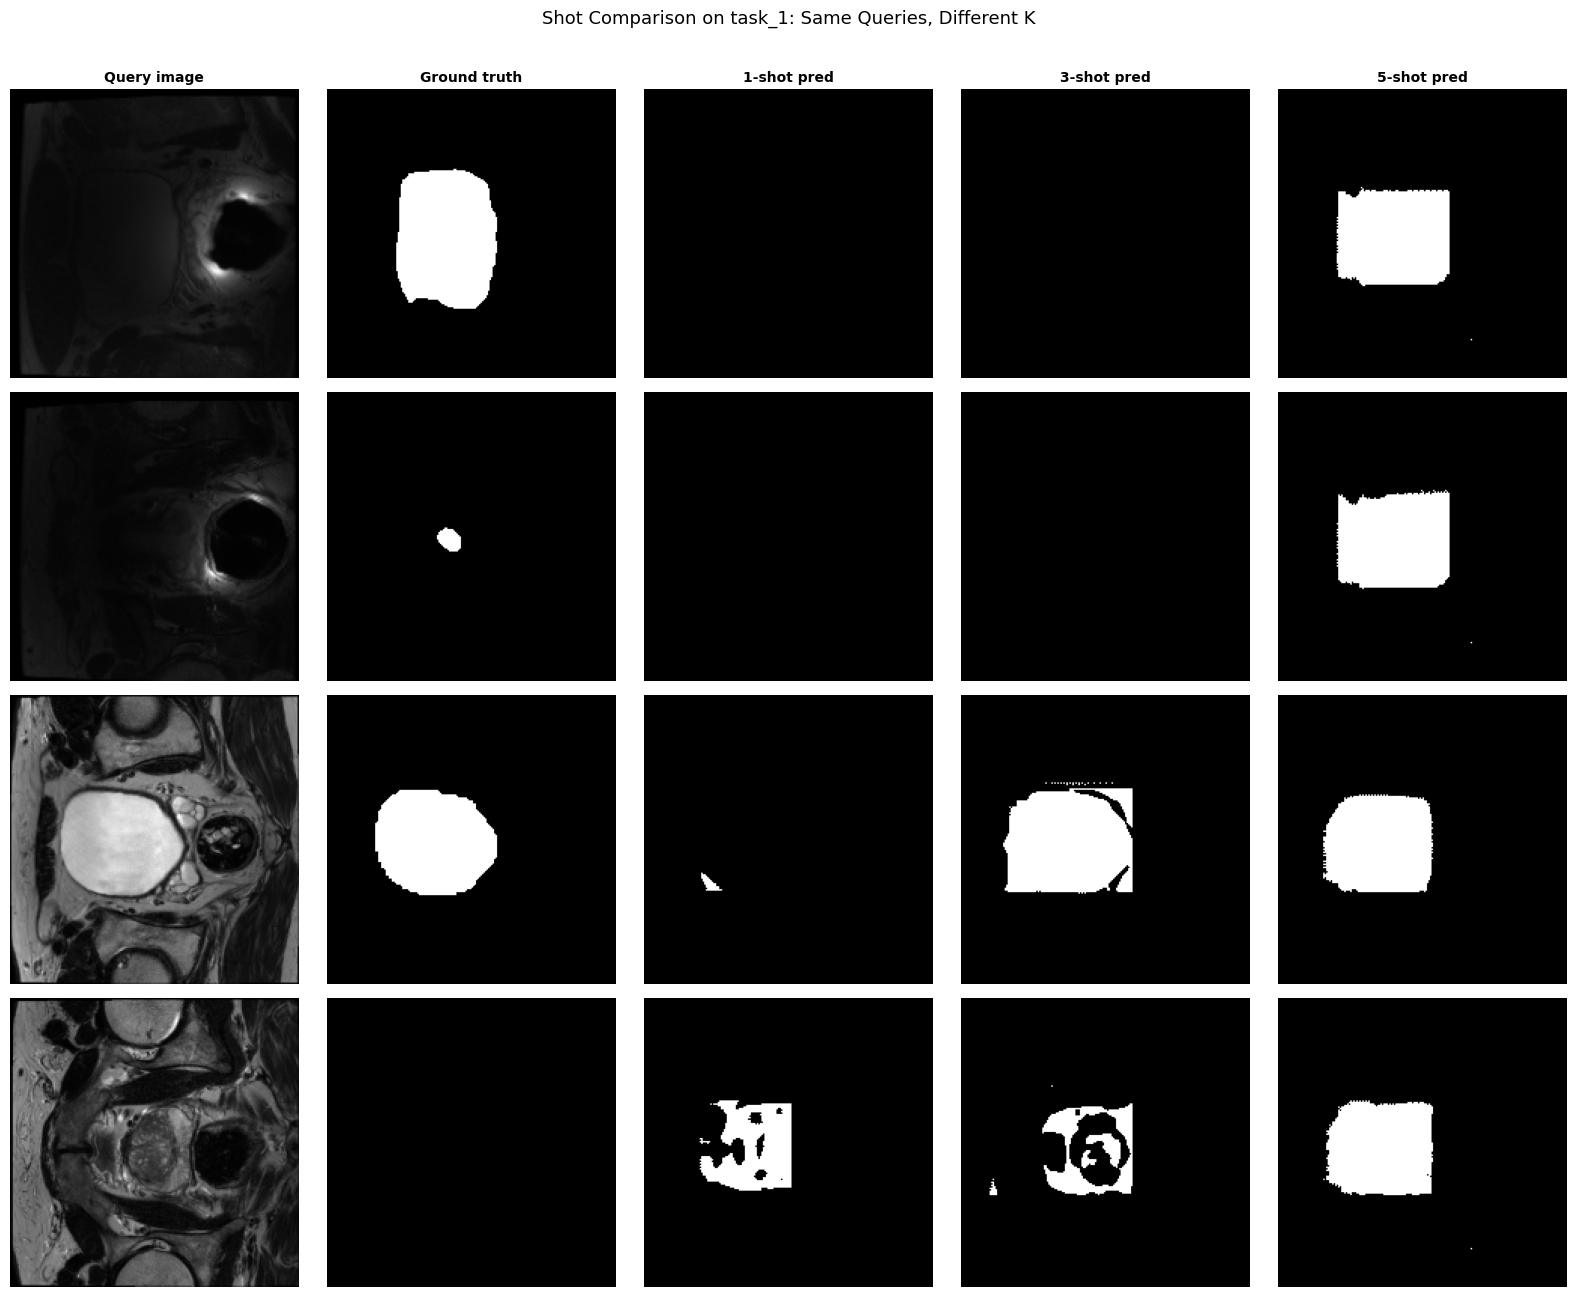

Saved: shot_comparison.png


In [ ]:
## 12 · Shot comparison: 1-shot vs 3-shot vs 5-shot (same queries)
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))

test_tasks = get_task_names("test")
task = test_tasks[0]

# Use the SAME query images for fair comparison
base_ep = sample_episode("test", task, k=5, query_size=4, seed=99)
q_imgs = base_ep["query_images"]
q_msks = base_ep["query_masks"]

n_q = q_imgs.shape[0]
fig, axes = plt.subplots(n_q, 5, figsize=(16, 3.2 * n_q))
col_titles = ["Query image", "Ground truth", "1-shot pred", "3-shot pred", "5-shot pred"]

for ki, k in enumerate([1, 3, 5]):
    ep = sample_episode("test", task, k=k, query_size=None, seed=99)
    ad = adapt_task(model, ep["support_images"][:k], ep["support_masks"][:k], inner_iters=20, inner_lr=3e-3)
    ad.eval()
    with torch.no_grad():
        preds = (torch.sigmoid(ad(q_imgs.to(DEVICE))) > 0.5).float().cpu()

    for i in range(n_q):
        if ki == 0:
            axes[i,0].imshow(q_imgs[i].squeeze(0).numpy(), cmap="gray")
            axes[i,0].axis("off")
            axes[i,1].imshow(q_msks[i].squeeze(0).numpy(), cmap="gray")
            axes[i,1].axis("off")
        axes[i, ki+2].imshow(preds[i].squeeze(0).numpy(), cmap="gray")
        axes[i, ki+2].axis("off")

for j, t in enumerate(col_titles):
    axes[0, j].set_title(t, fontsize=10, fontweight="bold")

plt.suptitle(f"Shot Comparison on {task}: Same Queries, Different K", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("shot_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: shot_comparison.png")

In [ ]:
## 13 · Per-task breakdown
model = UNet().to(DEVICE)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))

test_tasks = get_task_names("test")
k_vals = [1, 3, 5, 10]

print(f"\n{'='*72}")
print(f"PER-TASK TEST RESULTS")
print(f"{'='*72}")
header = f"{'Task':<12}"
for k in k_vals:
    header += f"  {k}-shot Dice  {k}-shot IoU "
print(header)
print("-" * 72)

all_results = {}
for task in test_tasks:
    line = f"{task:<12}"
    all_results[task] = {}
    for k in k_vals:
        dices, ious = [], []
        for r in range(5):
            ep = sample_episode("test", task, k=k, query_size=10, seed=42+1000*r)
            ad = adapt_task(model, ep["support_images"], ep["support_masks"], 20, 3e-3)
            m = eval_query(ad, ep["query_images"], ep["query_masks"])
            dices.append(m["dice"]); ious.append(m["iou"])
        d, io = mean(dices), mean(ious)
        all_results[task][k] = {"dice": d, "iou": io}
        line += f"  {d:>9.4f}  {io:>8.4f} "
    print(line)

print("-" * 72)
avg_line = f"{'MEAN':<12}"
for k in k_vals:
    ad = mean(all_results[t][k]["dice"] for t in test_tasks)
    ai = mean(all_results[t][k]["iou"] for t in test_tasks)
    avg_line += f"  {ad:>9.4f}  {ai:>8.4f} "
print(avg_line)


PER-TASK TEST RESULTS
Task          1-shot Dice  1-shot IoU   3-shot Dice  3-shot IoU   5-shot Dice  5-shot IoU   10-shot Dice  10-shot IoU 
------------------------------------------------------------------------
task_1           0.3559    0.2656      0.3268    0.2490      0.3934    0.2844      0.3957    0.2980 
task_8           0.0547    0.0319      0.1043    0.0624      0.1004    0.0628      0.1814    0.1098 
------------------------------------------------------------------------
MEAN             0.2053    0.1487      0.2156    0.1557      0.2469    0.1736      0.2886    0.2039 


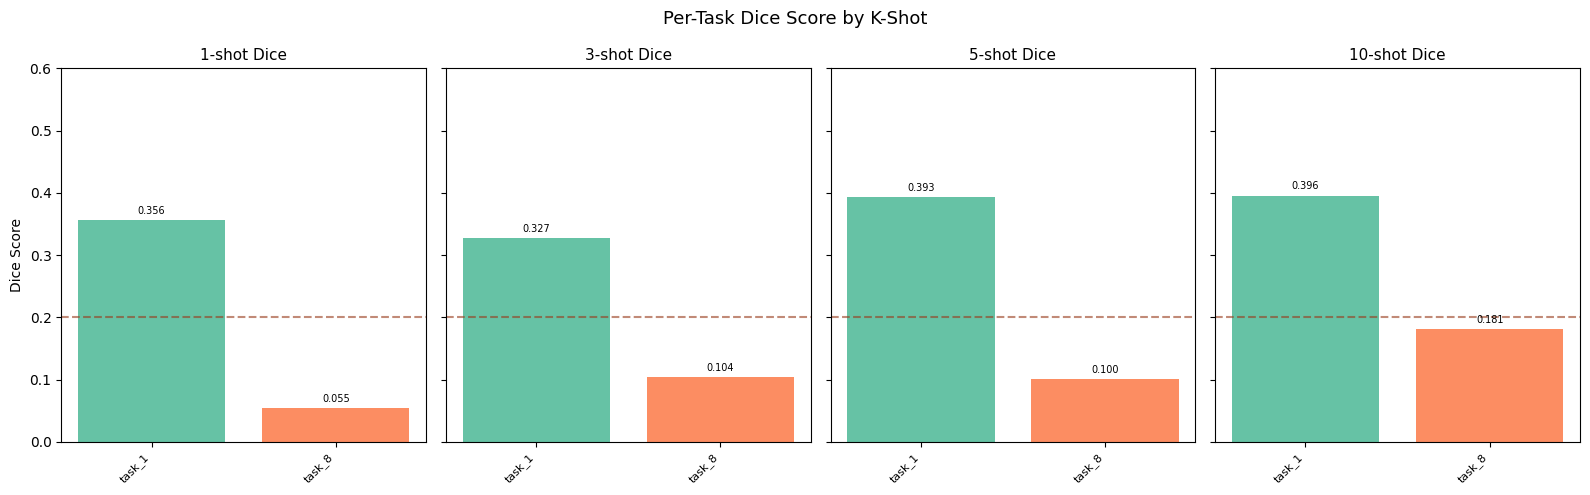

Saved: per_task_dice.png


In [ ]:
# Per-task Dice grouped bar chart for each k
fig, axes = plt.subplots(1, len(k_vals), figsize=(4*len(k_vals), 5), sharey=True)

for ki, k in enumerate(k_vals):
    task_names = list(all_results.keys())
    dice_vals = [all_results[t][k]["dice"] for t in task_names]
    colors = plt.cm.Set2(range(len(task_names)))
    axes[ki].bar(range(len(task_names)), dice_vals, color=colors)
    axes[ki].set_xticks(range(len(task_names)))
    axes[ki].set_xticklabels(task_names, rotation=45, ha="right", fontsize=8)
    axes[ki].set_title(f"{k}-shot Dice", fontsize=11)
    axes[ki].axhline(y=0.2, color="#993C1D", linestyle="--", alpha=0.6)
    axes[ki].set_ylim(0, max(0.6, max(dice_vals)*1.2))
    for i, v in enumerate(dice_vals):
        axes[ki].text(i, v+0.01, f"{v:.3f}", ha="center", fontsize=7)

axes[0].set_ylabel("Dice Score")
plt.suptitle("Per-Task Dice Score by K-Shot", fontsize=13)
plt.tight_layout()
plt.savefig("per_task_dice.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: per_task_dice.png")